In [2]:
import os
# Download the dataset and set up the local data folder
os.makedirs('data', exist_ok=True)
!wget -q -O data/WA_Fn-UseC_-Telco-Customer-Churn.csv https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
print('Dataset downloaded successfully.')

Dataset downloaded successfully.


In [3]:
# Create src directory and write the data_preprocessing.py script
os.makedirs('src', exist_ok=True)

with open('src/data_preprocessing.py', 'w') as f:
    f.write('''import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def load_data(filepath):
    return pd.read_csv(filepath)

def clean_data(df):
    df = df.copy()
    # TotalCharges contains some blank spaces
    df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])
    df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
    # Convert Churn to binary 1/0 for ease of modeling later if needed,
    # but we keep Churn as 'Yes'/'No' for EDA and change in encoding/preprocessing.
    return df

def engineer_features(df):
    df = df.copy()
    # Create a feature tracking the count of internet add-on services
    addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
    df['num_addons'] = (df[addons] == 'Yes').sum(axis=1)

    # Average monthly spend relative to tenure
    df['avg_monthly_spend'] = df['TotalCharges'] / (df['tenure'] + 1)

    # Tenure grouping
    def get_tenure_group(t):
        if t <= 12: return '0-12'
        elif t <= 24: return '12-24'
        elif t <= 48: return '24-48'
        else: return '48+'
    df['tenure_group'] = df['tenure'].apply(get_tenure_group)
    return df

def encode_features(df):
    df = df.copy()
    # We drop customerID as it's not a predictor
    if 'customerID' in df.columns:
        df = df.drop(columns=['customerID'])

    # Map binary target Churn
    if 'Churn' in df.columns and df['Churn'].dtype == 'object':
        df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

    # Map other binary features
    binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
    for col in binary_cols:
        if col in df.columns:
            df[col] = df[col].map({'Yes': 1, 'No': 0}).fillna(0)

    if 'Gender' in df.columns:
        df['Gender'] = df['Gender'].map({'Female': 1, 'Male': 0}).fillna(0)

    # One-hot encode remaining multi-class categorical columns
    cat_cols = df.select_dtypes(include=['object']).columns.tolist()
    df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
    return df

def preprocess(filepath):
    raw = load_data(filepath)
    clean = clean_data(raw)
    engineered = engineer_features(clean)
    encoded = encode_features(engineered)

    X = encoded.drop(columns=['Churn'])
    y = encoded['Churn']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # Scale features
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

    return X_train_scaled, X_test_scaled, y_train, y_test, scaler
''')
print('src/data_preprocessing.py file generated successfully.')

src/data_preprocessing.py file generated successfully.


# Telco Customer Churn – Capstone Analysis
**Business problem:** A telecom company is losing customers. We build models to predict which customers will churn so the retention team can target them with offers.

**Success metrics:** Accuracy is misleading because only ~27% of customers churn, so we focus on **F1-score, recall (catching churners) and ROC-AUC**.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns).

In [4]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# --- Paths (works locally and in Colab if the repo root is the working directory) ---
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())
DATA_PATH = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

from src import data_preprocessing as dp

## 1. Load and inspect the data

In [5]:
raw = dp.load_data(DATA_PATH)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
raw.info()
print("\nBlank TotalCharges:", (raw["TotalCharges"].astype(str).str.strip() == "").sum())
print("Duplicate rows:", raw.drop(columns="customerID").duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Exploratory Data Analysis

Overall churn rate: 26.5%


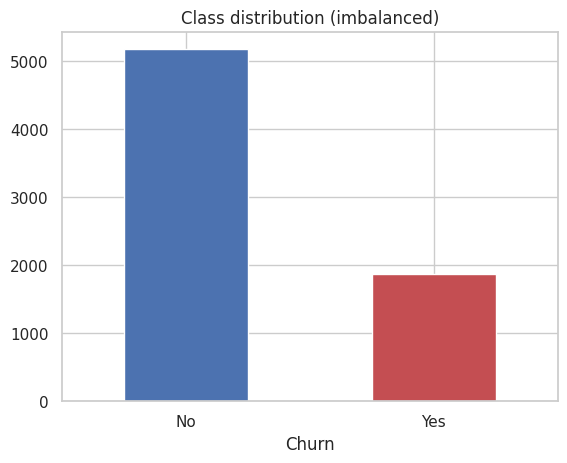

In [7]:
clean = dp.clean_data(raw)
churn_rate = (clean["Churn"] == "Yes").mean()
print(f"Overall churn rate: {churn_rate:.1%}")
ax = clean["Churn"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_title("Class distribution (imbalanced)"); plt.xticks(rotation=0)
plt.savefig(f"{FIG_DIR}/01_class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

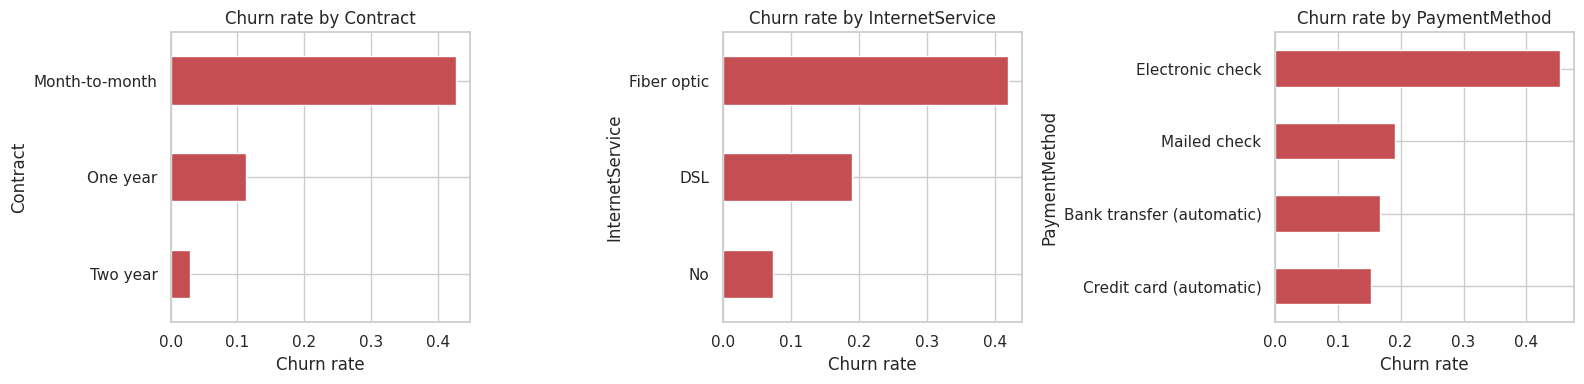

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = clean.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values()
    rate.plot(kind="barh", ax=ax, color="#C44E52")
    ax.set_title(f"Churn rate by {col}"); ax.set_xlabel("Churn rate")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_churn_by_category.png", dpi=150, bbox_inches="tight"); plt.show()

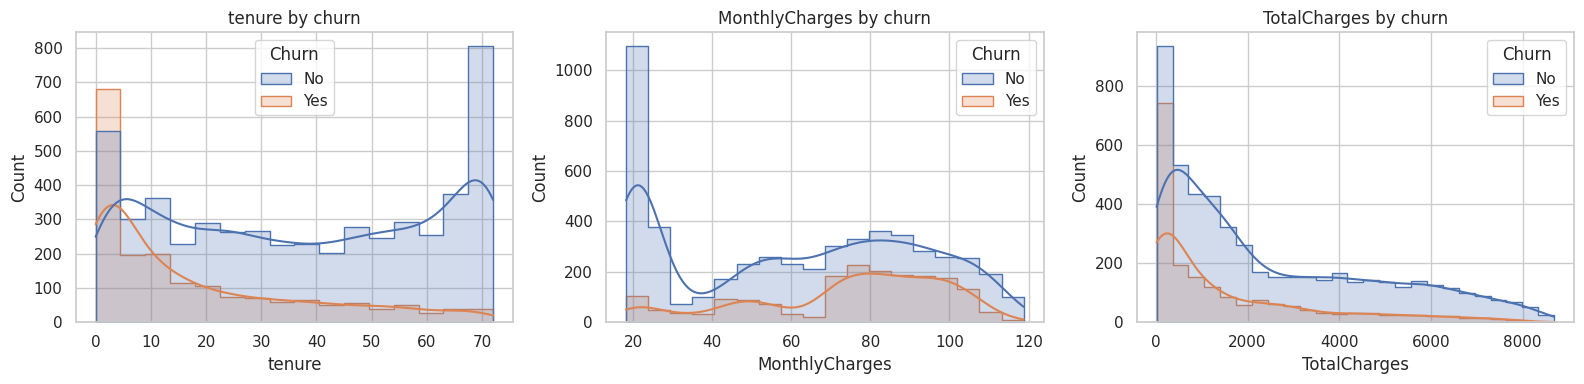

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=clean, x=col, hue="Churn", kde=True, ax=ax, element="step")
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_numeric_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

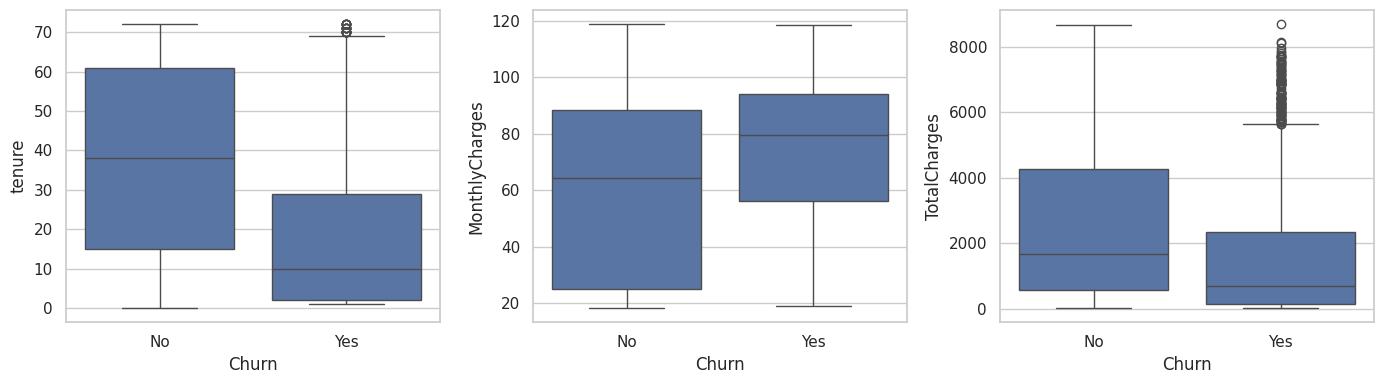

In [10]:
# Boxplots to visually check outliers
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=clean, y=col, x="Churn", ax=ax)
plt.tight_layout(); plt.show()

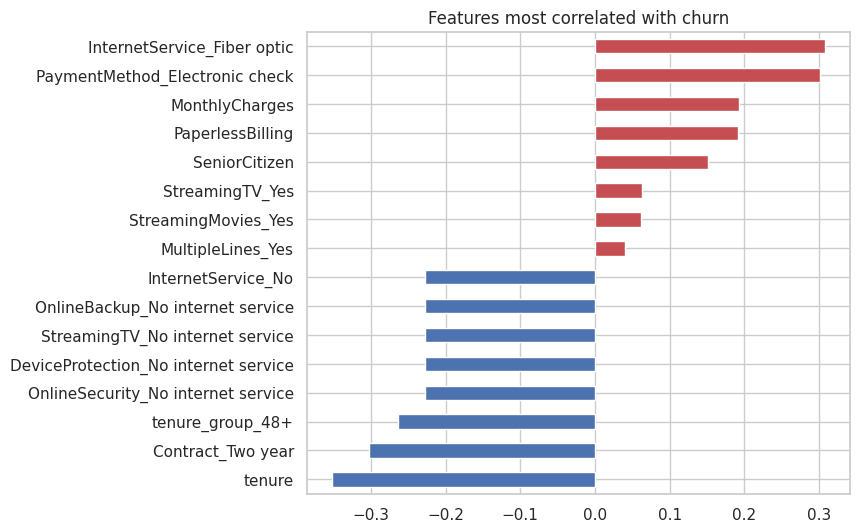

In [11]:
# Features most correlated with churn
encoded = dp.encode_features(dp.engineer_features(clean))
corr = encoded.corr()["Churn"].drop("Churn").sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])
plt.figure(figsize=(7, 6))
top.plot(kind="barh", color=["#4C72B0" if v < 0 else "#C44E52" for v in top])
plt.title("Features most correlated with churn")
plt.savefig(f"{FIG_DIR}/04_correlations.png", dpi=150, bbox_inches="tight"); plt.show()

### EDA takeaways
*(Edit this after running – replace with what YOUR charts show.)*
- Churn rate is about 27%, so the classes are imbalanced.
- Month-to-month contract customers churn far more than one/two-year customers.
- Customers with short tenure churn most; loyalty rises with tenure.
- Fiber optic and electronic-check customers show higher churn.
- Customers with more add-on services (security, tech support) churn less.

## 3. Preprocessing and feature engineering
All logic lives in `src/data_preprocessing.py`: cleaning, new features (`num_addons`, `avg_monthly_spend`, `tenure_group`), encoding, IQR outlier capping and scaling (fit on the training set only).

In [12]:
X_train, X_test, y_train, y_test, scaler = dp.preprocess(DATA_PATH)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
X_train.head()

Train: (5634, 35)  Test: (1409, 35)
Churn rate train/test: 0.265 0.265


,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,num_addons,avg_monthly_spend,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_12-24,tenure_group_24-48,tenure_group_48+
3738,-0.441773,-0.969234,-0.651557,0.102371,-3.013090,-1.202653,-0.521976,-0.263289,0.507935,-0.236288,...,-0.524081,1.247967,-0.512782,-0.563822,-0.523806,1.406903,-0.543846,-0.412129,1.835059,-0.682114
3151,-0.441773,1.031742,1.534786,-0.711743,0.331885,-1.202653,0.337478,-0.504814,-0.570530,0.182960,...,-0.524081,-0.801303,-0.512782,-0.563822,-0.523806,-0.710781,1.838757,2.426423,-0.544942,-0.682114
4860,-0.441773,1.031742,1.534786,-0.793155,-3.013090,-1.202653,-0.809013,-0.751213,0.507935,-0.322843,...,-0.524081,-0.801303,-0.512782,1.773611,-0.523806,-0.710781,1.838757,2.426423,-0.544942,-0.682114
3867,-0.441773,1.031742,-0.651557,-0.263980,0.331885,0.831495,0.284384,-0.173699,1.047168,0.159364,...,-0.524081,1.247967,-0.512782,1.773611,1.909105,-0.710781,-0.543846,-0.412129,1.835059,-0.682114
3810,-0.441773,1.031742,1.534786,-1.281624,0.331885,-1.202653,-0.676279,-0.990851,-1.109762,-0.660445,...,-0.524081,-0.801303,-0.512782,-0.563822,-0.523806,1.406903,-0.543846,-0.412129,-0.544942,-0.682114


## 4. Modeling
We compare a **Logistic Regression baseline** against a **tuned Random Forest**, both using `class_weight='balanced'` to handle the imbalance.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score)

# Baseline
baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
baseline.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [14]:
# Tuned Random Forest
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [5, 8, 12, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
}
search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_distributions=param_dist, n_iter=20, scoring="f1", cv=cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
rf = search.best_estimator_
print("Best params:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 4))

Best params: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 12}
Best CV F1: 0.6372


## 5. Evaluation

In [15]:
models = {"Logistic Regression (baseline)": baseline, "Random Forest (tuned)": rf}
rows = []
for name, m in models.items():
    pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results.to_csv("reports/model_comparison.csv")
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression (baseline),0.740,0.506,0.789,0.617,0.846
Random Forest (tuned),0.769,0.548,0.730,0.626,0.841


In [16]:
for name, m in models.items():
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, m.predict(X_test), target_names=["Stay", "Churn"]))

Logistic Regression (baseline)
              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Random Forest (tuned)
              precision    recall  f1-score   support

        Stay       0.89      0.78      0.83      1035
       Churn       0.55      0.73      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



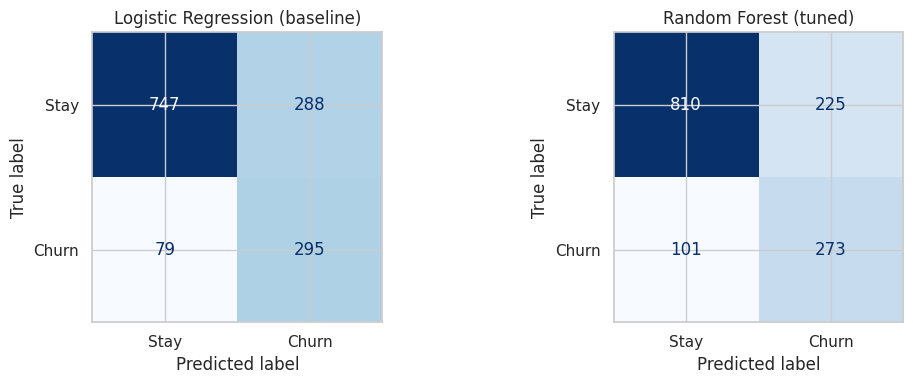

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Stay", "Churn"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

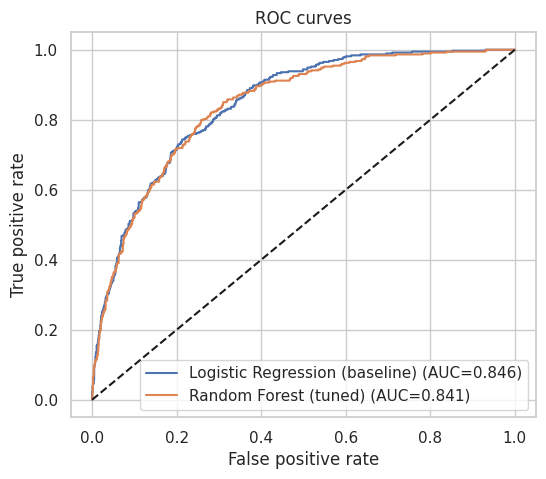

In [18]:
plt.figure(figsize=(6, 5))
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend()
plt.savefig(f"{FIG_DIR}/06_roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

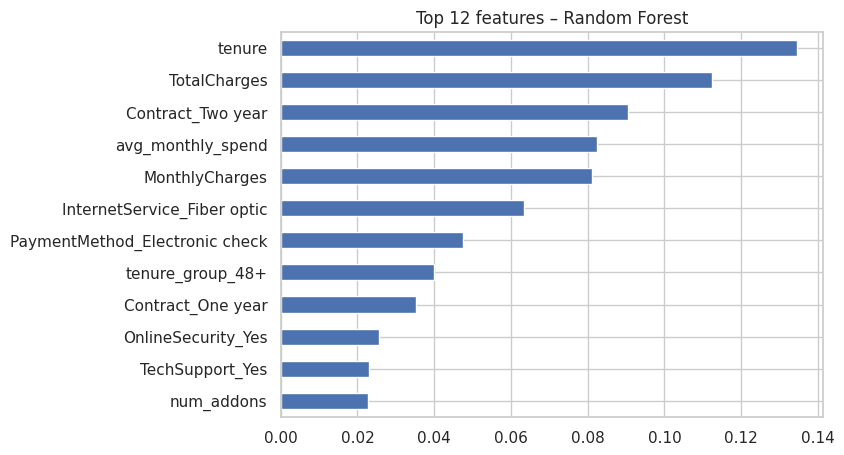

In [19]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(12)
plt.figure(figsize=(7, 5)); imp.plot(kind="barh", color="#4C72B0")
plt.title("Top 12 features – Random Forest")
plt.savefig(f"{FIG_DIR}/07_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Findings, limitations and future work
*(Edit with your real numbers after running.)*

**Findings**
- Compare the tuned Random Forest with the baseline using recall, F1 and ROC-AUC in the table above.
- Top churn drivers: contract type, tenure, monthly charges, internet service type.

**Business recommendations**
1. Offer discounts or upgrades to move month-to-month customers onto 1–2 year contracts.
2. Run an onboarding/retention programme for customers in their first 12 months.
3. Bundle tech support and online security, since customers with add-ons churn less.
4. Review fiber-optic pricing/quality and electronic-check payment friction.

**Limitations**
- Single snapshot of data (no time dimension); class imbalance; no cost-of-retention data.

**Future work**
- Try XGBoost/LightGBM, probability calibration, threshold tuning based on retention cost, SHAP explanations.